# Probabilistic Hough Transform Line Detection (OpenCV)

Notebook ini mengikuti alur implementasi Hough Transform dari artikel Analytics Vidhya.

Pipeline:

Original Image
→ Grayscale
→ Canny Edge Detection
→ Probabilistic Hough Transform (`cv2.HoughLinesP`)
→ Draw Detected Lines

Output HoughLinesP:

\[
(x_1,y_1,x_2,y_2)
\]

yang merepresentasikan koordinat awal dan akhir segmen garis.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


## 1. Load Image

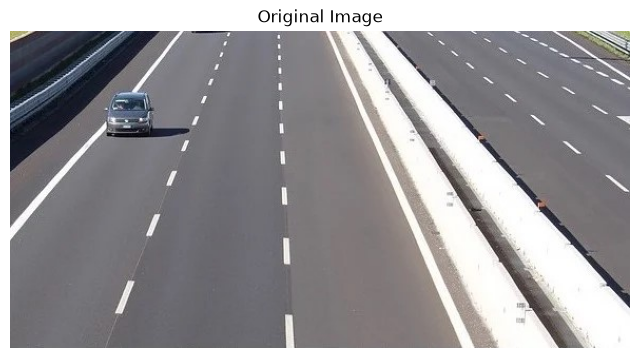

In [2]:
image_path = "line.png"

img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError(
        "Image tidak ditemukan. Pastikan file lane_hough.jpg tersedia."
    )

plt.figure(figsize=(8,5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off");


## 2. Convert Image to Grayscale

Hough Transform bekerja berdasarkan edge, sehingga citra RGB/BGR dikonversi menjadi grayscale.


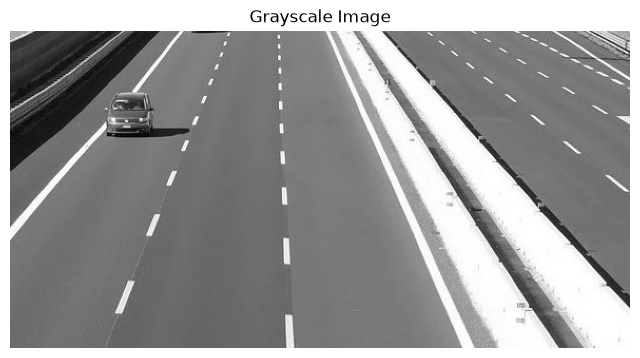

In [3]:
gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(8,5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off");


## 3. Canny Edge Detection

Canny menghasilkan pixel edge yang menjadi input untuk Hough Transform.


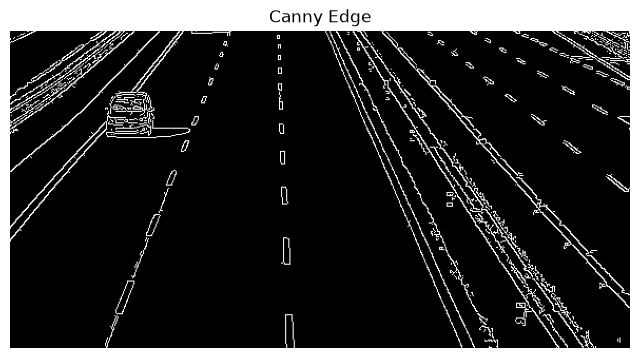

In [4]:
edges = cv2.Canny(
    gray,
    50,
    150
)

plt.figure(figsize=(8,5))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge")
plt.axis("off");


## 4. Probabilistic Hough Transform

Menggunakan:

`cv2.HoughLinesP()`

Parameter:

- threshold = jumlah vote minimum
- minLineLength = panjang minimum garis
- maxLineGap = jarak maksimum antar edge agar dianggap satu garis

Konfigurasi mengikuti contoh artikel:

- threshold = 68
- minLineLength = 15
- maxLineGap = 250


In [5]:
lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi/180,
    threshold=68,
    minLineLength=15,
    maxLineGap=250
)

if lines is None:
    print("Tidak ada garis ditemukan")
else:
    print("Jumlah garis:", len(lines))


Jumlah garis: 45


## 5. Extract Line Coordinates

Setiap garis memiliki format:

\[
[x_1,y_1,x_2,y_2]
\]



In [6]:
if lines is not None:
    for i, line in enumerate(lines[:10]):
        x1, y1, x2, y2 = line.reshape(4)
        print(
            f"Line {i+1}:",
            (x1,y1),
            (x2,y2)
        )

Line 1: (np.int32(332), np.int32(0)) (np.int32(522), np.int32(271))
Line 2: (np.int32(340), np.int32(25)) (np.int32(518), np.int32(300))
Line 3: (np.int32(353), np.int32(2)) (np.int32(587), np.int32(262))
Line 4: (np.int32(416), np.int32(74)) (np.int32(585), np.int32(261))
Line 5: (np.int32(309), np.int32(0)) (np.int32(462), np.int32(300))
Line 6: (np.int32(362), np.int32(10)) (np.int32(586), np.int32(250))
Line 7: (np.int32(0), np.int32(199)) (np.int32(160), np.int32(1))
Line 8: (np.int32(326), np.int32(53)) (np.int32(440), np.int32(299))
Line 9: (np.int32(0), np.int32(185)) (np.int32(154), np.int32(14))
Line 10: (np.int32(335), np.int32(0)) (np.int32(553), np.int32(300))


## 6. Draw Detected Lines

Garis hasil Hough digambar kembali pada citra asli.


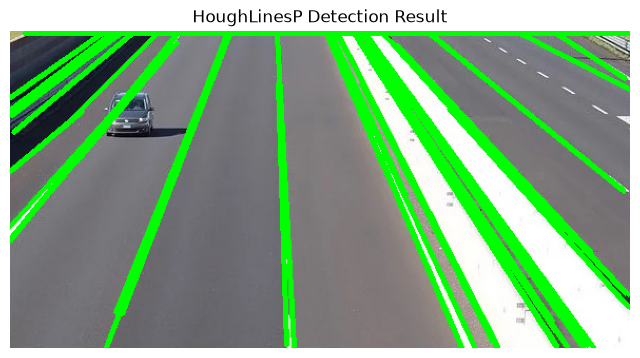

In [7]:
result = img.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)
        cv2.line(
            result,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

plt.figure(figsize=(8,5))
plt.imshow(
    cv2.cvtColor(
        result,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "HoughLinesP Detection Result"
)

plt.axis("off");

## 7. Comparison Original vs Result


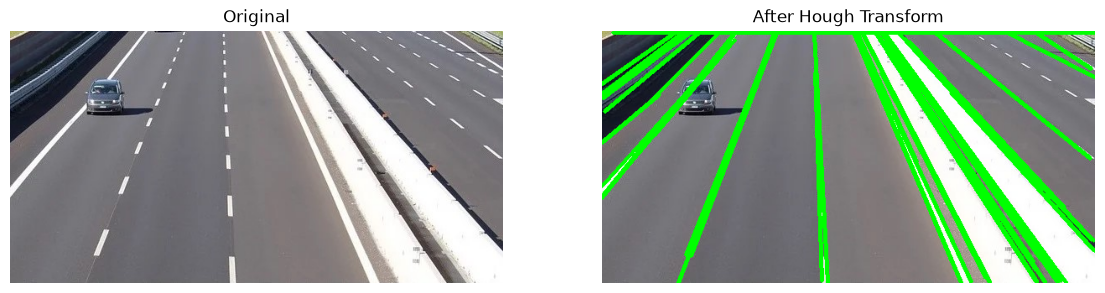

In [8]:
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("After Hough Transform")
plt.axis("off")

plt.show()


## 8. Parameter Experiment

Coba ubah parameter:

```python
threshold
minLineLength
maxLineGap
```

Efek umum:

- threshold naik → garis lebih sedikit tetapi lebih kuat
- threshold turun → garis lebih banyak tetapi noise meningkat
- minLineLength naik → hanya garis panjang dipertahankan
- maxLineGap naik → garis terputus lebih mudah digabungkan
